# 02 · JPEG from scratch

This notebook implements the lossy core of baseline JPEG with NumPy only, and compares it with OpenCV's codec (libjpeg) on a **rate–distortion curve** (bits per pixel vs PSNR).

Pipeline:

`RGB → YCbCr → 4:2:0 chroma subsampling → 8×8 blocks → level shift → 2-D DCT → quantise → zigzag → (entropy estimate)`
and the exact inverse for decoding.

Only quantisation discards information (plus the colour detail removed by chroma subsampling); every other step is exactly invertible. Real Huffman coding is not implemented: the file size is **estimated** from the entropy of the coded symbols. This is enough to compare quality settings, but it slightly underestimates real file sizes.

Runs on CPU.

In [1]:
import os, glob
import numpy as np
import cv2
import matplotlib.pyplot as plt
from scipy.fft import dctn, idctn   # used only to check the codec, never inside it

# BSD500 val images (Kaggle path); elsewhere, set the BSD_VAL environment variable to a local copy of images/val
DATA_DIR = os.environ.get("BSD_VAL", "/kaggle/input/datasets/balraj98/berkeley-segmentation-dataset-500-bsds500/images/val")
paths = sorted(glob.glob(os.path.join(DATA_DIR, "*.jpg")))

def load_rgb(path):
    return cv2.imread(path, cv2.IMREAD_COLOR)[:, :, ::-1].astype(np.float32)   # 0-255 here, JPEG works in 8-bit

def crop16(im):
    H, W = (im.shape[0] // 16) * 16, (im.shape[1] // 16) * 16
    return im[:H, :W]                       # multiple of 16 keeps 4:2:0 + 8x8 blocks simple

if paths:
    img = crop16(load_rgb(paths[0]))
else:                                       # no dataset: a built-in photo so the notebook still runs
    from skimage import data
    img = crop16(data.astronaut().astype(np.float32))
print(len(paths), "images found; working image", img.shape, "from", os.path.basename(paths[0]) if paths else "skimage")
# Note: BSD500 images are themselves stored as high-quality JPEGs, so "original" means "as distributed".

100 images found; working image (480, 320, 3) from 101085.jpg


## 1 · Colour transform and chroma subsampling

JPEG (JFIF) uses full-range YCbCr from BT.601:

$$Y = 0.299R + 0.587G + 0.114B,\quad C_b = 128 - 0.168736R - 0.331264G + 0.5B,\quad C_r = 128 + 0.5R - 0.418688G - 0.081312B$$

The transform is a 3 × 3 matrix plus an offset and is exactly invertible. **4:2:0 subsampling** then averages each 2 × 2 block of the two chroma channels. It costs little visible quality because the eye resolves fine detail in brightness far better than in colour, and natural images carry most of their detail in Y (notebook 01, section 6).

In [2]:
# Full-range BT.601 YCbCr as used by JPEG (JFIF)
M_YCC = np.array([[ 0.299,     0.587,     0.114   ],
                  [-0.168736, -0.331264,  0.5     ],
                  [ 0.5,      -0.418688, -0.081312]])
OFFSET = np.array([0.0, 128.0, 128.0])
M_INV = np.linalg.inv(M_YCC)                # exists because det(M) != 0: the transform loses nothing

def rgb_to_ycbcr(img):
    return img @ M_YCC.T + OFFSET           # a 3x3 matrix multiply per pixel + offset

def ycbcr_to_rgb(ycc):
    return (ycc - OFFSET) @ M_INV.T

def subsample_420(c):
    """Average each 2x2 block -> half resolution in both axes."""
    H, W = c.shape
    return c.reshape(H // 2, 2, W // 2, 2).mean(axis=(1, 3))

def upsample_420(c, method="bilinear"):
    """Back to full resolution. 'nearest' repeats each value in a 2x2 block; 'bilinear' interpolates
    between neighbouring chroma samples (closer to libjpeg's smoothed "fancy" upsampling).
    At high quality this choice dominates the error: see the ablation in Experiment 4."""
    if method == "nearest":
        return np.repeat(np.repeat(c, 2, axis=0), 2, axis=1)
    return cv2.resize(c.astype(np.float32), (c.shape[1] * 2, c.shape[0] * 2), interpolation=cv2.INTER_LINEAR).astype(np.float64)

# Checks
assert np.allclose(ycbcr_to_rgb(rgb_to_ycbcr(img)), img, atol=1e-3)
print("colour transform round-trips; det(M) =", round(np.linalg.det(M_YCC), 4))

colour transform round-trips; det(M) = 0.2363


## 2 · The 8×8 DCT as a matrix

The orthonormal DCT-II matrix $C \in \mathbb{R}^{N\times N}$ has entries

$$C_{k,n} = \alpha_k \cos\left(\frac{\pi (2n+1) k}{2N}\right),\quad \alpha_0 = \sqrt{1/N},\ \alpha_{k>0} = \sqrt{2/N}$$

so a 2-D block transform is $F = C\,B\,C^\top$ and the inverse is $B = C^\top F\,C$.

Because $C$ is orthonormal ($CC^\top = I$), the inverse is just the transpose, and the transform preserves energy (Parseval's theorem): the sum of squared pixels equals the sum of squared coefficients. The checks below verify orthonormality, agreement with `scipy.fft.dctn` (used only for checking), invertibility and energy preservation.

In [3]:
def dct_matrix(N=8):
    """Orthonormal DCT-II matrix: C[k, n] = a_k cos(pi (2n + 1) k / 2N)."""
    k = np.arange(N)[:, None]; n = np.arange(N)[None, :]
    C = np.sqrt(2.0 / N) * np.cos(np.pi * (2 * n + 1) * k / (2 * N))
    C[0, :] = np.sqrt(1.0 / N)
    return C

def dct2(block, C):
    return C @ block @ C.T                  # works on (..., 8, 8) stacks too (matmul broadcasts)

def idct2(coeffs, C):
    return C.T @ coeffs @ C                 # orthonormal: the inverse is the transpose

C = dct_matrix(8)
b = np.random.default_rng(0).uniform(-128, 127, (8, 8))
assert np.allclose(C @ C.T, np.eye(8), atol=1e-10), "C is not orthonormal"
assert np.allclose(dct2(b, C), dctn(b, norm="ortho")), "dct2 disagrees with scipy"
assert np.allclose(idct2(dct2(b, C), C), b), "idct2 is not the inverse"
assert np.isclose((b ** 2).sum(), (dct2(b, C) ** 2).sum()), "energy not preserved (Parseval)"
print("DCT checks pass (orthonormal, matches scipy, invertible, preserves energy)")

DCT checks pass (orthonormal, matches scipy, invertible, preserves energy)


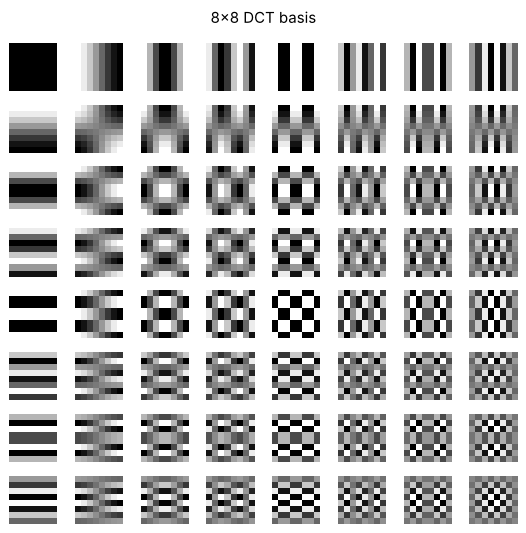

In [4]:
# Visualise the 64 basis images: basis (u, v) is the outer product of rows u and v of C
fig, axes = plt.subplots(8, 8, figsize=(6, 6))
for u in range(8):
    for v in range(8):
        axes[u, v].imshow(np.outer(C[u], C[v]), cmap="gray"); axes[u, v].axis("off")
plt.suptitle("8x8 DCT basis"); plt.tight_layout(); plt.show()

## 3 · Quantisation

Standard luminance and chrominance tables (ITU-T T.81, Annex K). Quality scaling follows the IJG convention used by libjpeg:

$$s = \begin{cases}5000/q & q < 50\\ 200 - 2q & q \ge 50\end{cases},\qquad Q_q = \mathrm{clip}\left(\left\lfloor \frac{Q\,s + 50}{100}\right\rfloor, 1, 255\right)$$

Step sizes grow towards high frequencies and are coarser for chroma. Rounding $F / Q_q$ to the nearest integer is the one step that discards information.

In [5]:
Q_LUMA = np.array([
    [16, 11, 10, 16, 24, 40, 51, 61],
    [12, 12, 14, 19, 26, 58, 60, 55],
    [14, 13, 16, 24, 40, 57, 69, 56],
    [14, 17, 22, 29, 51, 87, 80, 62],
    [18, 22, 37, 56, 68, 109, 103, 77],
    [24, 35, 55, 64, 81, 104, 113, 92],
    [49, 64, 78, 87, 103, 121, 120, 101],
    [72, 92, 95, 98, 112, 100, 103, 99]], dtype=np.float32)

Q_CHROMA = np.full((8, 8), 99, dtype=np.float32)
Q_CHROMA[:4, :4] = [[17, 18, 24, 47], [18, 21, 26, 66], [24, 26, 56, 99], [47, 66, 99, 99]]

def scale_qtable(Q, quality):
    """IJG (libjpeg) quality scaling."""
    q = min(max(int(quality), 1), 100)
    s = 5000 / q if q < 50 else 200 - 2 * q
    return np.clip(np.floor((Q * s + 50) / 100), 1, 255).astype(np.float32)

def quantise(F, Qq):
    return np.round(F / Qq)

def dequantise(Fq, Qq):
    return Fq * Qq

assert scale_qtable(Q_LUMA, 50).tolist() == Q_LUMA.tolist(), "quality 50 should give the base table"
print("step sizes, luma DC / highest AC:", {q: (scale_qtable(Q_LUMA, q)[0, 0], scale_qtable(Q_LUMA, q)[7, 7]) for q in (10, 50, 90)})

step sizes, luma DC / highest AC: {10: (np.float32(80.0), np.float32(255.0)), 50: (np.float32(16.0), np.float32(99.0)), 90: (np.float32(3.0), np.float32(20.0))}


## 4 · Zigzag + entropy estimate

Zigzag orders the coefficients from low to high frequency, so the many zeros at the end of a block cluster together. Size is estimated as (number of symbols) × (empirical entropy of the symbol stream): the ideal code length that Huffman coding approaches.

In [6]:
def zigzag_indices(N=8):
    """(row, col) in zigzag order: anti-diagonals by increasing i + j, alternating direction."""
    return sorted(((i, j) for i in range(N) for j in range(N)),
                  key=lambda p: (p[0] + p[1], p[1] if (p[0] + p[1]) % 2 == 0 else p[0]))

def entropy_bits(symbols):
    """Shannon entropy (bits/symbol) of an integer stream times its length = ideal code length."""
    symbols = np.asarray(symbols).ravel()
    if symbols.size == 0:
        return 0.0
    _, counts = np.unique(symbols, return_counts=True)
    p = counts / counts.sum()
    return float(-(p * np.log2(p)).sum() * symbols.size)

zz = zigzag_indices()
ZZ_R, ZZ_C = np.array([p[0] for p in zz]), np.array([p[1] for p in zz])
assert zz[:6] == [(0, 0), (0, 1), (1, 0), (2, 0), (1, 1), (0, 2)]
assert entropy_bits([3, 3, 3, 3]) == 0 and abs(entropy_bits([0, 1]) - 2) < 1e-12
print("zigzag and entropy checks pass")

zigzag and entropy checks pass


## 5 · Full encoder / decoder

`my_jpeg` chains every step: colour transform, chroma subsampling, level shift, DCT and quantisation per 8 × 8 block, then the exact inverse, with the decoded image rounded and clipped to 8 bits as a real decoder outputs.

Two size estimates are compared. `channel_bits_simple` takes the entropy of DC differences and of every AC value. `channel_bits` follows JPEG's symbol structure: DC is coded as the difference from the previous block, and AC coefficients as (zero-run, size) symbols plus amplitude bits, with ZRL for 16 zeros and one end-of-block symbol for the trailing zeros. `opencv_jpeg` is the reference, with the real file size.

In [7]:
def blockify(ch):
    """(H, W) -> (H/8, W/8, 8, 8) without loops."""
    H, W = ch.shape
    return ch.reshape(H // 8, 8, W // 8, 8).swapaxes(1, 2)

def unblockify(blocks):
    h, w = blocks.shape[:2]
    return blocks.swapaxes(1, 2).reshape(h * 8, w * 8)

def encode_channel(ch, Qq):
    """Level shift, DCT, quantise one channel. Returns quantised coefficient blocks."""
    return quantise(dct2(blockify(ch) - 128.0, C), Qq)

def decode_channel(Fq, Qq):
    return unblockify(idct2(dequantise(Fq, Qq), C)) + 128.0

def size_cat(v):
    """JPEG size category: number of bits needed for |v| (0 for v == 0)."""
    v = np.abs(np.asarray(v, dtype=np.int64))
    return np.where(v == 0, 0, np.floor(np.log2(np.maximum(v, 1))).astype(np.int64) + 1)

def channel_bits_simple(Fq):
    """Naive estimate: entropy of DC differences + entropy of every AC value (zeros included)."""
    dc = Fq[..., 0, 0].ravel()
    return entropy_bits(np.diff(dc, prepend=0)) + entropy_bits(Fq[..., ZZ_R[1:], ZZ_C[1:]])

def channel_bits(Fq):
    """JPEG-style estimate. DC: difference to the previous block, coded as (size category, then that many bits).
    AC: walk the zigzag; each non-zero value becomes a (zero-run, size) symbol plus `size` amplitude bits,
    16 zeros = ZRL, trailing zeros = one EOB symbol. Symbol entropy stands in for the Huffman code."""
    blocks = Fq.reshape(-1, 8, 8)
    dcd = np.diff(blocks[:, 0, 0], prepend=0); dsz = size_cat(dcd)
    bits = entropy_bits(dsz) + dsz.sum()
    ac = blocks[:, ZZ_R[1:], ZZ_C[1:]]
    syms, amp = [], 0
    for row in ac:
        prev = -1
        for k in np.flatnonzero(row):
            run = k - prev - 1
            while run > 15:
                syms.append(0xF0); run -= 16          # ZRL: a run of 16 zeros
            sz = int(size_cat(row[k])); syms.append(run * 16 + sz); amp += sz
            prev = k
        if prev < 62:
            syms.append(0x00)                           # EOB: the rest of the block is zero
    return bits + entropy_bits(syms) + amp

def my_jpeg(img, quality, subsample=True, upsample="bilinear", bits_fn=None):
    """Encode + decode. Return (reconstructed rgb as 8-bit values, estimated bits)."""
    bits_fn = bits_fn or channel_bits
    ycc = rgb_to_ycbcr(img)
    QY, QC = scale_qtable(Q_LUMA, quality), scale_qtable(Q_CHROMA, quality)
    bits, rec = 0.0, []
    for c in range(3):
        ch = ycc[..., c]
        if c > 0 and subsample:
            ch = subsample_420(ch)
        Q = QY if c == 0 else QC
        Fq = encode_channel(ch, Q)
        bits += bits_fn(Fq)
        out = decode_channel(Fq, Q)
        rec.append(upsample_420(out, upsample) if (c > 0 and subsample) else out)
    rgb = ycbcr_to_rgb(np.stack(rec, axis=-1))
    return np.clip(np.round(rgb), 0, 255), bits           # a decoder outputs 8-bit pixels

def opencv_jpeg(img, quality):
    ok, buf = cv2.imencode(".jpg", img[:, :, ::-1].astype(np.uint8), [cv2.IMWRITE_JPEG_QUALITY, quality])
    rec = cv2.imdecode(buf, cv2.IMREAD_COLOR)[:, :, ::-1].astype(np.float32)
    return rec, 8 * len(buf)

def psnr255(a, b):
    mse = np.mean((a.astype(np.float64) - b) ** 2)
    return 10 * np.log10(255 ** 2 / mse)

rec, bits = my_jpeg(img, 50)
print(f"quality 50: {bits / (img.shape[0] * img.shape[1]):.3f} bits per pixel, PSNR {psnr255(img, rec):.2f} dB")

quality 50: 1.410 bits per pixel, PSNR 27.90 dB


## 6 · Experiments

1. **Rate–distortion curve:** bits per pixel vs PSNR for this codec and OpenCV, qualities 5–95.
2. **Energy compaction:** the average |coefficient| per zigzag position on a log scale, and the cumulative energy.
3. **Artifacts at quality 10:** blocking and ringing, shown on a crop and measured across block boundaries.
4. **Ablation:** chroma subsampling on vs off, with two ways of upsampling the chroma back.

 q   ours bpp (run-length)  naive bpp  ours dB | OpenCV bpp  OpenCV dB
  5    0.180                0.250    21.26  |   0.301      21.28
 10    0.378                0.530    23.22  |   0.492      23.23
 20    0.698                0.948    25.17  |   0.804      25.18
 30    0.967                1.268    26.27  |   1.062      26.26
 40    1.192                1.524    27.15  |   1.279      27.15
 50    1.410                1.763    27.90  |   1.495      27.90
 60    1.647                2.011    28.71  |   1.731      28.69
 70    2.003                2.371    29.85  |   2.087      29.84
 80    2.576                2.920    31.60  |   2.673      31.58
 90    3.760                3.998    34.87  |   3.929      34.82
 95    4.936                5.139    48.85  |   5.215      49.78


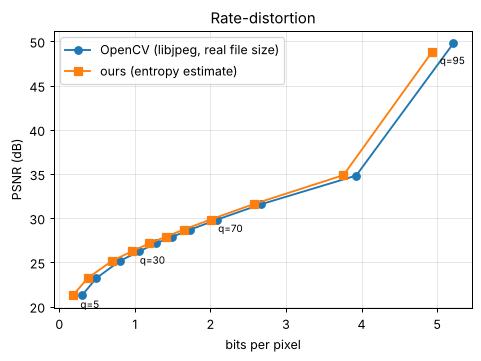

In [8]:
# Experiment 1 · rate-distortion curve on the working image
qualities = [5, 10, 20, 30, 40, 50, 60, 70, 80, 90, 95]
pixels = img.shape[0] * img.shape[1]
mine, ocv = [], []
for q in qualities:
    r1, b1 = my_jpeg(img, q); r2, b2 = opencv_jpeg(img, q)
    _, b0 = my_jpeg(img, q, bits_fn=channel_bits_simple)
    mine.append((b1 / pixels, psnr255(img, r1), b0 / pixels)); ocv.append((b2 / pixels, psnr255(img, r2)))
mine, ocv = np.array(mine), np.array(ocv)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(ocv[:, 0], ocv[:, 1], "o-", label="OpenCV (libjpeg, real file size)")
ax.plot(mine[:, 0], mine[:, 1], "s-", label="ours (entropy estimate)")
for q, (x, y, _) in zip(qualities, mine):
    if q in (5, 30, 70, 95): ax.annotate(f"q={q}", (x, y), textcoords="offset points", xytext=(6, -10), fontsize=8)
ax.set_xlabel("bits per pixel"); ax.set_ylabel("PSNR (dB)"); ax.set_title("Rate-distortion"); ax.legend(); ax.grid(alpha=0.3)
plt.show()

print(" q   ours bpp (run-length)  naive bpp  ours dB | OpenCV bpp  OpenCV dB")
for q, m, o in zip(qualities, mine, ocv):
    print(f"{q:3d}   {m[0]:6.3f}               {m[2]:6.3f}   {m[1]:6.2f}  |  {o[0]:6.3f}     {o[1]:6.2f}")

**Is this codec as good as libjpeg?** Two ways to compare: at the same quality setting (same quantisation tables, so PSNR should be almost identical), and at the same bit rate (PSNR at matched bpp, by interpolating along each curve). Averaging over 20 validation images makes the numbers less dependent on one photo.

The matched-bit-rate comparison favours this codec because its size is an ideal entropy estimate with no headers, while OpenCV's is a real file; it is an artefact of the estimate, not a better codec.

In [9]:
from numpy import interp
n_imgs = min(20, len(paths)) if paths else 1
imgs20 = [crop16(load_rgb(p)) for p in paths[:n_imgs]] if paths else [img]
same_q, same_rate, bpp_ratio = [], [], []
for im in imgs20:
    px = im.shape[0] * im.shape[1]
    m = np.array([(my_jpeg(im, q)[1] / px, psnr255(im, my_jpeg(im, q)[0])) for q in qualities])
    o = np.array([(opencv_jpeg(im, q)[1] / px, psnr255(im, opencv_jpeg(im, q)[0])) for q in qualities])
    same_q.append(m[:, 1] - o[:, 1])                       # dB difference at equal quality setting
    bpp_ratio.append(m[:, 0] / o[:, 0])                    # our estimated size / real file size
    grid = np.linspace(max(m[0, 0], o[0, 0]), min(m[-1, 0], o[-1, 0]), 20)
    same_rate.append(np.mean(interp(grid, m[:, 0], m[:, 1]) - interp(grid, o[:, 0], o[:, 1])))
same_q, bpp_ratio = np.array(same_q), np.array(bpp_ratio)
print(f"{n_imgs} images")
print(f"PSNR, ours minus OpenCV at the same quality: mean {same_q.mean():+.2f} dB (range {same_q.min():+.2f} to {same_q.max():+.2f})")
print(f"size, ours / OpenCV at the same quality:    mean {bpp_ratio.mean():.2f}x (q=10: {bpp_ratio[:, 1].mean():.2f}x, q=90: {bpp_ratio[:, 9].mean():.2f}x)")
print(f"PSNR, ours minus OpenCV at the same bit rate: mean {np.mean(same_rate):+.2f} dB")

20 images
PSNR, ours minus OpenCV at the same quality: mean -0.11 dB (range -4.78 to +0.19)
size, ours / OpenCV at the same quality:    mean 0.86x (q=10: 0.69x, q=90: 0.95x)
PSNR, ours minus OpenCV at the same bit rate: mean +0.88 dB


### Experiment 2 · Energy compaction

The DCT concentrates a natural block's energy in a few low-frequency coefficients, which is why quantising the
rest costs little. Measured on the unquantised luma DCT of the working image.

energy in DC alone: 84.6%; in the first 6 of 64 coefficients: 92.5%; first 15: 95.7%
of the AC energy alone, the first 5 AC coefficients hold 51.0% and the first 14 hold 72.2%
at quality 50, 73.8% of all luma coefficients quantise to exactly 0


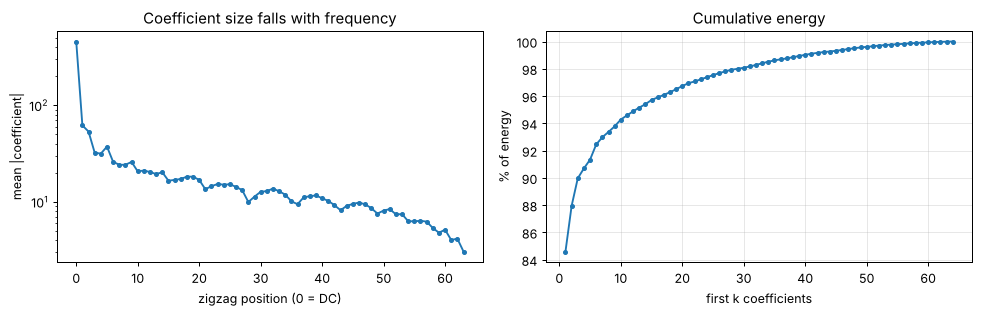

In [10]:
F = dct2(blockify(rgb_to_ycbcr(img)[..., 0]) - 128.0, C)       # (h, w, 8, 8) unquantised luma coefficients
mag = np.abs(F[..., ZZ_R, ZZ_C]).reshape(-1, 64).mean(0)         # mean |coef| per zigzag position
energy = (F[..., ZZ_R, ZZ_C] ** 2).reshape(-1, 64).sum(0)
cum = np.cumsum(energy) / energy.sum()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].semilogy(mag, "o-", ms=3); axes[0].set_xlabel("zigzag position (0 = DC)"); axes[0].set_ylabel("mean |coefficient|")
axes[0].set_title("Coefficient size falls with frequency")
axes[1].plot(np.arange(1, 65), cum * 100, "o-", ms=3); axes[1].set_xlabel("first k coefficients"); axes[1].set_ylabel("% of energy")
axes[1].set_title("Cumulative energy"); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()
ac_cum = np.cumsum(energy[1:]) / energy[1:].sum()
print(f"energy in DC alone: {cum[0]:.1%}; in the first 6 of 64 coefficients: {cum[5]:.1%}; first 15: {cum[14]:.1%}")
print(f"of the AC energy alone, the first 5 AC coefficients hold {ac_cum[4]:.1%} and the first 14 hold {ac_cum[13]:.1%}")
zero_frac = (encode_channel(rgb_to_ycbcr(img)[..., 0], scale_qtable(Q_LUMA, 50)) == 0).mean()
print(f"at quality 50, {zero_frac:.1%} of all luma coefficients quantise to exactly 0")

### Experiment 3 · Artifacts at quality 10

Blocking: each 8×8 block is coded independently, so coarse quantisation leaves visible steps at block edges.
Ringing: dropping high frequencies near a sharp edge truncates its Fourier series (the Gibbs phenomenon), leaving
ripples beside the edge. The crop below shows both.

q=10: pixel steps across 8x8 block boundaries average 19.13, inside blocks 8.92 (2.1x)
original image: 15.48 vs 15.84 (no block structure)


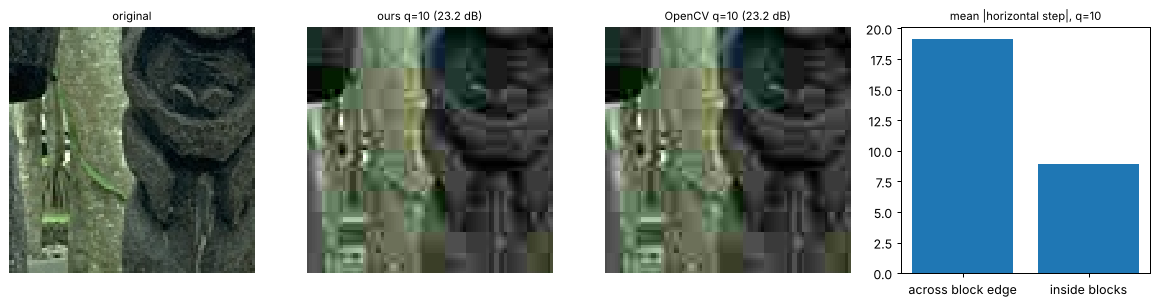

In [11]:
r10, _ = my_jpeg(img, 10)
r10_cv, _ = opencv_jpeg(img, 10)
y0, x0 = img.shape[0] // 3, img.shape[1] // 3
crop = (slice(y0, y0 + 96), slice(x0, x0 + 96))
fig, axes = plt.subplots(1, 4, figsize=(13, 3.5))
blk = np.abs(np.diff(r10[..., 1].astype(np.float64), axis=1))       # horizontal steps in the G channel
for ax, im, t in zip(axes[:3], [img, r10, r10_cv], ["original", f"ours q=10 ({psnr255(img, r10):.1f} dB)", f"OpenCV q=10 ({psnr255(img, r10_cv):.1f} dB)"]):
    ax.imshow(im[crop].astype(np.uint8), interpolation="nearest"); ax.set_title(t, fontsize=9); ax.axis("off")
cols = np.arange(blk.shape[1])
edge = blk[:, cols % 8 == 7].mean(); inner = blk[:, cols % 8 != 7].mean()
axes[3].bar(["across block edge", "inside blocks"], [edge, inner]); axes[3].set_title("mean |horizontal step|, q=10", fontsize=9)
plt.tight_layout(); plt.show()
orig_steps = np.abs(np.diff(img[..., 1].astype(np.float64), axis=1))
print(f"q=10: pixel steps across 8x8 block boundaries average {edge:.2f}, inside blocks {inner:.2f} ({edge / inner:.1f}x)")
print(f"original image: {orig_steps[:, cols % 8 == 7].mean():.2f} vs {orig_steps[:, cols % 8 != 7].mean():.2f} (no block structure)")

### Experiment 4 · Ablation: what does 4:2:0 chroma subsampling buy, and what does it cost?

Compared against coding chroma at full resolution, with two ways of upsampling the chroma back.

In [12]:
print(" q   bits saved by 4:2:0   PSNR cost (bilinear up)   PSNR cost (nearest up)")
for q in (30, 50, 75, 90, 95):
    r_s, b_s = my_jpeg(img, q, subsample=True); r_f, b_f = my_jpeg(img, q, subsample=False)
    r_n, _ = my_jpeg(img, q, subsample=True, upsample="nearest")
    print(f"{q:3d}   {1 - b_s / b_f:6.1%}               {psnr255(img, r_f) - psnr255(img, r_s):+.2f} dB"
          f"                  {psnr255(img, r_f) - psnr255(img, r_n):+.2f} dB")

 q   bits saved by 4:2:0   PSNR cost (bilinear up)   PSNR cost (nearest up)
 30     8.1%               +0.17 dB                  +0.21 dB
 50     8.9%               +0.19 dB                  +0.25 dB
 75    10.0%               +0.32 dB                  +0.41 dB
 90    10.3%               +0.65 dB                  +0.84 dB
 95    10.0%               +0.27 dB                  +4.91 dB


## Findings

- **My codec vs OpenCV at the same quality:** PSNR is the same up to q = 90 (27.90 vs 27.90 dB at q = 50, 34.87 vs 34.82 dB at q = 90). At q = 95 a gap opens (48.85 vs 49.78 dB on the working image), because small differences in chroma upsampling and rounding are no longer hidden by the quantisation error.
- **Size:** my estimate is 0.86× the real file size on average (0.69× at q = 10). The estimate uses ideal entropy, which beats real Huffman tables, and it doesn't count file headers. That is why my curve looks +0.88 dB better at the same bit rate; it doesn't mean my codec is better.
- **Energy compaction:** the DC coefficient alone holds 84.6% of the luma energy, and the first 6 of 64 coefficients hold 92.5%. At q = 50, 73.8% of the luma coefficients become exactly zero. This is why JPEG can throw so much away and still look good.
- **Blocking at q = 10:** the jumps between neighbouring pixels across 8 × 8 block edges are 2.1× bigger than inside the blocks (19.13 vs 8.92). The original image has no such pattern (15.48 vs 15.84).
- **4:2:0 subsampling** saves 8–10% of the bits and costs only 0.17–0.65 dB with bilinear upsampling. With nearest upsampling, the cost at q = 95 jumps to 4.91 dB.